# Does the UCI-HAR model work on adults 70+ (HAR70+)?
The model (`rf_mag_uci.joblib`) was trained on UCI-HAR (adults aged 19-48, phone at the waist) using only acceleration **magnitude** features.
Here we run it, unchanged, on HAR70+ (adults 70+, **back** sensor only) and see how well it does.

Both datasets are in g at 50 Hz (checked below).

In [1]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from features import WIN, HOP, magnitude, mag_features   # same feature code used for training

har70_dir = Path('../../data/open datasets/HAR 70')
model = joblib.load('rf_mag_uci.joblib')
print('model loaded:', model)

model loaded: RandomForestClassifier(max_depth=5, n_estimators=10, random_state=42)


## Check units and sampling rate

In [2]:
# read one subject and look at the time between samples
one = pd.read_csv(har70_dir / '501.csv', parse_dates=['timestamp'])
gap_ms = one['timestamp'].diff().dt.total_seconds().median() * 1000
print(f'HAR70+ time between samples: {gap_ms:.0f} ms  ->  {1000 / gap_ms:.0f} Hz')

# if a sensor is in g, its magnitude is about 1 when it is still (gravity only)
still = one[one['label'].isin([6, 7])]    # standing / sitting
mag_still = magnitude(still['back_x'], still['back_y'], still['back_z'])
print(f'HAR70+ magnitude while standing/sitting: {np.median(mag_still):.2f}  (about 1.0 means g)')
print('UCI-HAR is 50 Hz and total_acc is in g (a still person reads about 1.0 too)')

HAR70+ time between samples: 20 ms  ->  50 Hz
HAR70+ magnitude while standing/sitting: 0.98  (about 1.0 means g)
UCI-HAR is 50 Hz and total_acc is in g (a still person reads about 1.0 too)


## Cut HAR70+ into windows
* Only the **back** sensor is used.
* Windows are 128 samples long and move forward 64 samples at a time (same as UCI-HAR).
* Windows are cut inside one subject's file only, never across two files.
* A window is kept only if **every** sample in it has the same label.
* Labels (from the HAR70+ description): 1 walking, 3 shuffling, 4 stairs up, 5 stairs down, 6 standing, 7 sitting, 8 lying.

In [3]:
all_mags = []      # magnitude windows
all_labels = []    # one original label per window
dropped_mixed = 0  # windows that contain more than one label
dropped_gap = 0    # windows with a time gap in the recording

for file in sorted(har70_dir.glob('5*.csv')):
    df = pd.read_csv(file, parse_dates=['timestamp'])
    mag = magnitude(df['back_x'], df['back_y'], df['back_z'])
    label = df['label'].to_numpy()
    secs = df['timestamp'].astype('int64').to_numpy() / 1e9      # time in seconds

    for start in range(0, len(df) - WIN + 1, HOP):
        end = start + WIN
        window_labels = label[start:end]
        if window_labels.min() != window_labels.max():            # label changes inside the window
            dropped_mixed += 1
            continue
        if secs[end - 1] - secs[start] > 3.0:                     # 127 samples should take about 2.54 s
            dropped_gap += 1
            continue
        all_mags.append(mag[start:end])
        all_labels.append(window_labels[0])

mags = np.array(all_mags)
orig_labels = np.array(all_labels)
print('windows kept:', len(mags), '| dropped (mixed labels):', dropped_mixed, '| dropped (time gap):', dropped_gap)

windows kept: 30411 | dropped (mixed labels): 4814 | dropped (time gap): 53


## Merge labels (walking vs resting) and drop shuffling

In [4]:
# walking, stairs up, stairs down -> 1 (walking)    standing, sitting, lying -> 0 (resting)
# shuffling (3) is not in the dictionary, so it gets dropped
to_two = {1: 1, 4: 1, 5: 1, 6: 0, 7: 0, 8: 0}
names = {1: 'walking', 3: 'shuffling', 4: 'stairs up', 5: 'stairs down', 6: 'standing', 7: 'sitting', 8: 'lying'}

print('Windows per original activity (before dropping shuffling):')
print(pd.Series(orig_labels).map(names).value_counts().to_string())

keep = np.isin(orig_labels, list(to_two))
X = mag_features(mags[keep])                                # 5 features per window
y = pd.Series(orig_labels[keep]).map(to_two).to_numpy()

print('\nWindows used for testing:', len(y))
print(pd.Series(y).map({0: 'resting', 1: 'walking'}).value_counts().to_string())

Windows per original activity (before dropping shuffling):
walking        15240
sitting         7409
standing        4334
lying           3131
shuffling        227
stairs up         36
stairs down       34

Windows used for testing: 30184
walking    15310
resting    14874


## Results

              precision    recall  f1-score   support

     resting       0.87      1.00      0.93     14874
     walking       1.00      0.86      0.92     15310

    accuracy                           0.93     30184
   macro avg       0.93      0.93      0.93     30184
weighted avg       0.93      0.93      0.93     30184



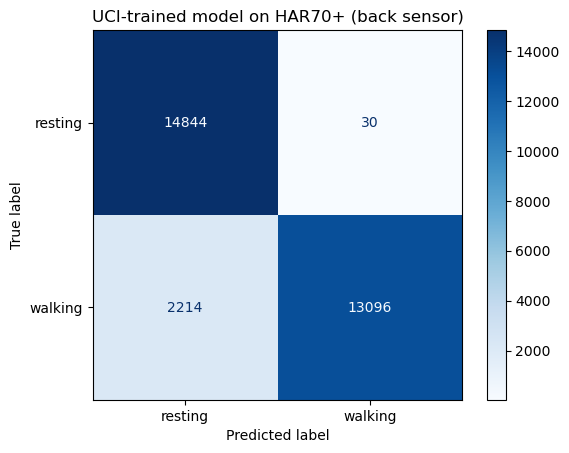

In [5]:
pred = model.predict(X)

print(classification_report(y, pred, target_names=['resting', 'walking']))

cm = confusion_matrix(y, pred)
ConfusionMatrixDisplay(cm, display_labels=['resting', 'walking']).plot(cmap='Blues')
plt.title('UCI-trained model on HAR70+ (back sensor)')
plt.show()

## Sanity checks (is there data leakage?)
Six checks on the result above (93% accuracy, walking recall 0.86). The setup cell rebuilds the variables the checks need.

In [6]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, recall_score, balanced_accuracy_score
from features import FEATURE_NAMES

uci_dir = Path('../../data/open datasets/UCI HAR Dataset')
STD_COL = 'mag_std'     # magnitude std feature
MEAN_COL = 'mag_mean'   # magnitude mean feature

# ---- UCI training data as a table (0 = resting, 1 = walking) ----
uci_axes = [pd.read_csv(uci_dir / 'train' / 'Inertial Signals' / f'total_acc_{a}_train.txt',
                        sep=r'\s+', header=None).to_numpy() for a in 'xyz']
X_uci = pd.DataFrame(mag_features(magnitude(*uci_axes)), columns=FEATURE_NAMES)
uci_to_two = {1: 1, 2: 1, 3: 1, 4: 0, 5: 0, 6: 0}
y_uci = pd.read_csv(uci_dir / 'train' / 'y_train.txt', header=None)[0].map(uci_to_two).to_numpy()

# ---- HAR70+ windows again, this time remembering which subject each window came from ----
# Same rules as before. We also keep EVERY window (even mixed or gappy ones) in har_raw,
# so the purity check in step 4 can count them.
feat_rows, feat_labels, feat_subj = [], [], []          # windows we test on
other_mags, other_lbl = [], []                          # shuffling windows (dropped from the test)
raw_ts, raw_label, raw_subj, raw_wid = [], [], [], []   # every sample of every window
window_id = 0
offsets = np.arange(WIN)

for file in sorted(har70_dir.glob('5*.csv')):
    df = pd.read_csv(file, parse_dates=['timestamp'])
    mag = magnitude(df['back_x'], df['back_y'], df['back_z'])
    label = df['label'].to_numpy()
    ts = df['timestamp'].to_numpy()
    secs = df['timestamp'].astype('int64').to_numpy() / 1e9

    starts = np.arange(0, len(df) - WIN + 1, HOP)
    idx = starts[:, None] + offsets                      # shape (n_windows, 128): sample numbers

    # remember every sample of every window
    raw_ts.append(ts[idx].ravel())
    raw_label.append(label[idx].ravel())
    raw_subj.append(np.full(idx.size, file.stem))
    raw_wid.append(np.repeat(np.arange(window_id, window_id + len(starts)), WIN))
    window_id += len(starts)

    # decide which windows are usable (same rules as before)
    win_labels = label[idx]
    pure = win_labels.min(axis=1) == win_labels.max(axis=1)
    no_gap = (secs[idx[:, -1]] - secs[idx[:, 0]]) <= 3.0
    ok = pure & no_gap
    first = win_labels[:, 0]

    use = ok & np.isin(first, list(to_two))             # walking / stairs / standing / sitting / lying
    feat_rows.append(mag_features(mag[idx[use]]))
    feat_labels.append(pd.Series(first[use]).map(to_two).to_numpy())
    feat_subj.append(np.full(use.sum(), file.stem))

    shuf = ok & (first == 3)                            # shuffling windows
    other_mags.append(mag[idx[shuf]])
    other_lbl.append(first[shuf])

X_new = pd.DataFrame(np.vstack(feat_rows), columns=FEATURE_NAMES)
y_new = np.concatenate(feat_labels)
subj = np.concatenate(feat_subj)
X_other = pd.DataFrame(mag_features(np.vstack(other_mags)), columns=FEATURE_NAMES)
other_lbl = np.concatenate(other_lbl)

har_raw = pd.DataFrame({'timestamp': np.concatenate(raw_ts), 'label': np.concatenate(raw_label),
                        'subject': np.concatenate(raw_subj), 'window_id': np.concatenate(raw_wid)})

# make sure this rebuild is identical to the windows used above
assert np.array_equal(y_new, y) and np.allclose(X_new.to_numpy(), X), 'rebuilt windows differ from the ones above'
X, y = X_new, y_new                       # from now on X is a table with column names
y_uci = np.asarray(y_uci)

pred = model.predict(X.to_numpy())        # .to_numpy() because the model was trained on plain arrays
print('windows:', len(y), '| subjects:', len(np.unique(subj)), '| UCI training windows:', len(y_uci))

windows: 30184 | subjects: 18 | UCI training windows: 7352


### 1. Dumb baseline: one threshold on magnitude std
The threshold is picked on UCI only, then applied to HAR70+. If this gets close to 93%, the model isn't adding much beyond "is the person moving?".

In [7]:
# try many thresholds on the UCI data and keep the one with the best accuracy
cands = np.quantile(X_uci[STD_COL], np.linspace(0.01, 0.99, 199))
uci_acc = [accuracy_score(y_uci, (X_uci[STD_COL] > t).astype(int)) for t in cands]
thr = cands[int(np.argmax(uci_acc))]
base_pred = (X[STD_COL] > thr).astype(int).values     # 1 = walking if std is above the threshold

print(f'threshold (picked on UCI only): {thr:.4f}')
print(f'baseline on HAR70+: acc={accuracy_score(y, base_pred):.3f}  walking recall={recall_score(y, base_pred):.3f}')
print(f'model    on HAR70+: acc={accuracy_score(y, pred):.3f}  walking recall={recall_score(y, pred):.3f}')

threshold (picked on UCI only): 0.1159
baseline on HAR70+: acc=0.864  walking recall=0.733
model    on HAR70+: acc=0.926  walking recall=0.855


### 2. Per-subject breakdown
The 93% is an average. What matters is the spread, especially walking recall.

In [8]:
df = pd.DataFrame({'subject': subj, 'y': y, 'pred': pred})
df['correct'] = df.y == df.pred
per = pd.DataFrame({
    'n':           df.groupby('subject').size(),
    'acc':         df.groupby('subject')['correct'].mean(),
    'walk_recall': df[df.y == 1].groupby('subject')['correct'].mean(),
    'rest_recall': df[df.y == 0].groupby('subject')['correct'].mean(),
})
print(per.sort_values('walk_recall').round(3))
print('\n', per[['acc', 'walk_recall']].describe().round(3))

            n    acc  walk_recall  rest_recall
subject                                       
514      1324  0.503        0.032        0.998
505      1123  0.877        0.540        1.000
513      1609  0.782        0.574        0.994
512      1409  0.895        0.801        0.989
515      2161  0.940        0.824        0.999
510      1640  0.919        0.833        1.000
518      1938  0.929        0.843        0.997
516      1697  0.948        0.911        1.000
507      1580  0.957        0.928        0.997
517      1885  0.960        0.930        0.996
506      1721  0.960        0.933        0.997
511      1693  0.975        0.952        1.000
502      1811  0.972        0.955        0.996
503      1607  0.978        0.956        1.000
508      1769  0.974        0.958        1.000
509      1647  0.986        0.971        1.000
501      1458  0.982        0.972        1.000
504      2112  0.988        0.975        0.998

           acc  walk_recall
count  18.000       18.000
mean

### 3. Preprocessing matches between datasets
Units and gravity, sampling rate, window length, and whether a scaler was fitted on the right data.

In [9]:
# 3a. units + gravity: resting magnitude should sit near 1.0 g in BOTH datasets
print('resting median mag_mean  UCI:', round(X_uci.loc[y_uci == 0, MEAN_COL].median(), 3),
      '| HAR70+:', round(X.loc[y == 0, MEAN_COL].median(), 3), '(both should be ~1.0)')

# 3b. sampling rate (UCI is 50 Hz)
ts = pd.to_datetime(har_raw['timestamp'])
dt = ts.groupby(har_raw['subject']).diff().dt.total_seconds().median()
print(f'HAR70+ sampling rate ~ {1/dt:.1f} Hz (UCI: 50 Hz)')

# 3c. window length (UCI: 128 samples)
print('samples per window (count of windows):')
print(har_raw.groupby('window_id').size().value_counts().head())

# 3d. scaler must be fitted on UCI, only applied to HAR70+
if hasattr(model, 'named_steps'):
    sc = next((s for s in model.named_steps.values() if hasattr(s, 'mean_')), None)
    if sc is not None:
        print('scaler mean == UCI mean   :', np.allclose(sc.mean_, X_uci.mean().values))
        print('scaler mean == HAR70+ mean:', np.allclose(sc.mean_, X.mean().values), '(should be False)')
else:
    print('3d. model is a plain random forest with no scaler, so there is nothing that could have been fitted on HAR70+')

resting median mag_mean  UCI: 1.024 | HAR70+: 0.999 (both should be ~1.0)
HAR70+ sampling rate ~ 50.0 Hz (UCI: 50 Hz)
samples per window (count of windows):
128    35278
Name: count, dtype: int64
3d. model is a plain random forest with no scaler, so there is nothing that could have been fitted on HAR70+


### 4. Label mapping and window purity
Which original activities exist, how many windows span two activities, and what the model does with the shuffling windows we left out. `har_raw` here is every window before any were dropped.

In [10]:
HAR70_CODES = {1: 'walking', 3: 'shuffling', 4: 'stairs up', 5: 'stairs down',
               6: 'standing', 7: 'sitting', 8: 'lying'}
print('original activity counts (samples, overlapping windows count twice):')
print(har_raw['label'].map(HAR70_CODES).value_counts(), '\n')

# purity = share of the most common label inside each window (1.0 = the window has one activity)
purity = har_raw.groupby('window_id')['label'].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print(f'mixed windows: {(purity < 1).sum()} of {len(purity)} ({(purity < 1).mean():.1%})')

# what does the model call the shuffling windows we dropped? (shuffling matters for elderly users)
print('\nshuffling windows (not in the test above):')
print(pd.crosstab(pd.Series(other_lbl).map(HAR70_CODES), model.predict(X_other.to_numpy()),
                  colnames=['predicted (0=rest, 1=walk)']))

original activity counts (samples, overlapping windows count twice):
label
walking        2157884
sitting         966904
standing        833360
lying           406364
shuffling       131996
stairs down       9956
stairs up         9120
Name: count, dtype: int64 

mixed windows: 4814 of 35278 (13.6%)

shuffling windows (not in the test above):
predicted (0=rest, 1=walk)    0   1
row_0                              
shuffling                   216  11


### 5. Look at the missed walking windows
If HAR70+ walking sits between UCI walking and resting, the slow-gait explanation holds.

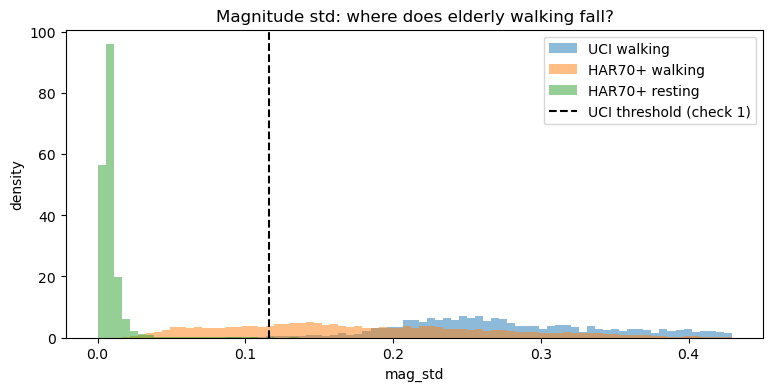

median mag_std  caught walking: 0.1900 | missed walking: 0.0586 | resting: 0.0067

missed walking windows by subject:
514    657
513    346
512    140
505    138
518    135
510    133
515    128
516     89
517     72
506     67
Name: count, dtype: int64


In [11]:
hi = np.quantile(np.concatenate([X_uci[STD_COL], X[STD_COL]]), 0.99)
bins = np.linspace(0, hi, 80)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(X_uci.loc[y_uci == 1, STD_COL], bins, alpha=.5, density=True, label='UCI walking')
ax.hist(X.loc[y == 1, STD_COL],         bins, alpha=.5, density=True, label='HAR70+ walking')
ax.hist(X.loc[y == 0, STD_COL],         bins, alpha=.5, density=True, label='HAR70+ resting')
ax.axvline(thr, ls='--', c='k', label='UCI threshold (check 1)')
ax.set_xlabel(STD_COL); ax.set_ylabel('density'); ax.legend()
ax.set_title('Magnitude std: where does elderly walking fall?')
plt.show()

missed = (y == 1) & (pred == 0)    # real walking, model said resting
caught = (y == 1) & (pred == 1)    # real walking, model said walking
print(f'median {STD_COL}  caught walking: {X.loc[caught, STD_COL].median():.4f}'
      f' | missed walking: {X.loc[missed, STD_COL].median():.4f}'
      f' | resting: {X.loc[y == 0, STD_COL].median():.4f}')
print('\nmissed walking windows by subject:')
print(pd.Series(subj[missed]).value_counts().head(10))

### 6. Shuffled-label control
Retrain on UCI with shuffled labels and test on HAR70+. It should land near chance (~0.5). If it scores well, something is leaking.

In [12]:
rng = np.random.default_rng(0)
m_shuf = clone(model).fit(X_uci.to_numpy(), rng.permutation(y_uci))   # same model, but the labels are scrambled
p_shuf = m_shuf.predict(X.to_numpy())
print(f'shuffled-label model on HAR70+: acc={accuracy_score(y, p_shuf):.3f}  '
      f'balanced acc={balanced_accuracy_score(y, p_shuf):.3f}  (expect ~0.5)')

shuffled-label model on HAR70+: acc=0.395  balanced acc=0.400  (expect ~0.5)


### Evaluation
the result holds up (no leakage, consistent preprocessing), but the model trained on young adults misses low-intensity gait. That shows up as missed slow walking in a few subjects and almost no detection of shuffling.
The next step that follows is to train with some elderly data. Train on part of the HAR70+ subjects and test on the rest, still holding out whole people. Then see how much walking recall and shuffling detection improve.